# GPT-2 + LoRA na PolEmo2

In [2]:
from google.colab import drive
drive.mount("/content/drive")

OUT = "/content/drive/MyDrive/nlp_lab/outputs"
AUG = "/content/drive/MyDrive/nlp_lab/augmented"

Mounted at /content/drive


In [3]:
%cd /content
!git clone -b gpt2 https://github.com/mtorzynska/nlp_language_models_lab.git || git -C nlp_language_models_lab pull
%cd /content/nlp_language_models_lab
# bez -U: aktualizacja moze podmienic torch z cuda na wersje bez cuda
!pip install -q "transformers>=5" "datasets>=4" peft accelerate umap-learn
# stara preinstalowana torchao psuje import peft, lora jej nie potrzebuje
!pip uninstall -y -q torchao
!python -m src.data.prepare

import torch
print(torch.__version__, torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "BRAK GPU")

/content
Cloning into 'nlp_language_models_lab'...
remote: Enumerating objects: 169, done.
remote: Counting objects: 100% (169/169), done.
remote: Compressing objects: 100% (104/104), done.
remote: Total 169 (delta 77), reused 138 (delta 50), pack-reused 0 (from 0)
Receiving objects: 100% (169/169), 2.14 MiB | 12.82 MiB/s, done.
Resolving deltas: 100% (77/77), done.
/content/nlp_language_models_lab
<frozen runpy>:130: RuntimeWarning: 'src.data.prepare' found in sys.modules after import of package 'src.data', but prior to execution of 'src.data.prepare'; this may result in unpredictable behaviour

all_text/train/0000.parquet: downloading bytes:  69% 2.49M/3.63M [00:00<00:00, 3.06MB/s,  130kB/s  ]
all_text/train/0000.parquet: downloading bytes: 100% 3.61M/3.61M [00:01<00:00, 3.46MB/s,  349kB/s  ]
all_text/train/0000.parquet: reconstructing file: 100% 3.63M/3.63M [00:01<00:00, 3.47MB/s,  352kB/s  ]
0000.parquet: 100% 447k/447k [00:00<00:00, 21.6MB/s]
0000.parquet: 100% 440k/440k [00:00<00

In [4]:
from pathlib import Path

for run in ["gpt2-text", "gpt2-text-head", "gpt2-token", "gpt2-text-augmented"]:
    path = Path(OUT) / run
    checkpoints = sorted((path / "checkpoints").glob("checkpoint-*"), key=lambda c: int(c.name.split("-")[1]))
    state = "gotowe" if (path / "results.json").exists() else f"przerwane ({checkpoints[-1].name})" if checkpoints else "brak"
    print(f"{run:22} {state}")
print(f"{'augmentacja':22} {'gotowe' if Path(AUG, 'augmented_gpt2_examples.md').exists() else 'brak'}")

gpt2-text              gotowe
gpt2-text-head         gotowe
gpt2-token             gotowe
gpt2-text-augmented    gotowe
augmentacja            gotowe


In [5]:
# do wyswietlania wyniko
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import silhouette_score

LABELS = ["zero", "minus", "plus", "amb"]
COLORS = {"zero": "#2a9d8f", "minus": "#264653", "plus": "#e76f51", "amb": "#457b9d"}
RUNS = {
    "gpt2-text": "tekst, LoRA",
    "gpt2-text-head": "tekst, head",
    "gpt2-text-augmented": "tekst, augmentacja",
    "gpt2-token": "tokeny, LoRA",
}


def metrics(run):
    # metryki testowe i macierz pomylek z results.json
    results = json.loads(Path(OUT, run, "results.json").read_text(encoding="utf-8"))
    test = results["test"]
    row = {
        "train": results["train_size"],
        "accuracy": test["test_accuracy"],
        "macro F1": test["test_f1_macro"],
        "weighted F1": test["test_f1_weighted"],
        **{f"F1 {label}": test[f"test_f1_{label}"] for label in LABELS},
    }
    return row, np.array(results["confusion_matrix"])


def styled(df):
    scores = [c for c in df.columns if c != "train"]
    return df.style.format("{:.3f}", subset=scores).background_gradient(cmap="Greens", subset=scores, vmin=0.4, vmax=1.0)


def plot_confusion(ax, cm, title):
    # liczby + procent wiersza (recall danej klasy)
    norm = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            ax.text(j, i, f"{cm[i, j]}\n{norm[i, j]:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if norm[i, j] > 0.5 else "black")
    ax.set_xticks(range(len(LABELS)), LABELS)
    ax.set_yticks(range(len(LABELS)), LABELS)
    ax.set_xlabel("predykcja")
    ax.set_ylabel("prawdziwa etykieta")
    ax.set_title(title)


def show_run(run):
    # wynik jednego przebiegu: tabela, f1 per klasa z macro f1, macierz pomylek
    row, cm = metrics(run)
    display(Markdown(f"### Wynik na zbiorze testowym: {RUNS[run]}"))
    display(styled(pd.DataFrame([row], index=[run])))
    fig, (ax, ax_cm) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.3, 1]})
    bars = ax.bar(LABELS, [row[f"F1 {label}"] for label in LABELS], color=[COLORS[label] for label in LABELS])
    ax.bar_label(bars, fmt="%.3f")
    ax.axhline(row["macro F1"], color="black", linestyle="--", linewidth=1.5)
    ax.text(3.45, row["macro F1"] + 0.03, f"macro F1 {row['macro F1']:.3f}", ha="right", fontweight="bold")
    ax.set_ylim(0, 1.08)
    ax.set_ylabel("F1")
    ax.set_title("F1 per klasa")
    ax.spines[["top", "right"]].set_visible(False)
    plot_confusion(ax_cm, cm, "macierz pomyłek")
    plt.tight_layout()
    plt.show()


def show_comparison(runs):
    # kilka przebiegow obok siebie, roznica macro f1 wzgledem pierwszego
    df = pd.DataFrame({RUNS[run]: metrics(run)[0] for run in runs}).T
    df["train"] = df["train"].astype(int)
    display(styled(df))
    for name, value in df["macro F1"].iloc[1:].items():
        display(Markdown(f"**{name}**: macro F1 {value - df['macro F1'].iloc[0]:+.3f} względem **{df.index[0]}**"))


def show_embeddings():
    # silhouette w przestrzeni 1024 wymiarow (cosinus) + accuracy glowicy na tych wektorach
    data = np.load(Path(OUT, "gpt2-text", "plots", "gpt2_embeddings.npz"))
    labels = data["labels"]
    df = pd.DataFrame({
        "silhouette (cosinus)": [silhouette_score(data[f"{v}_embeddings"], labels, metric="cosine") for v in ["base", "finetuned"]],
        "accuracy": [np.nan, (data["predictions"] == labels).mean()],
    }, index=["GPT-2 bazowy", "GPT-2 po strojeniu (LoRA)"])
    display(Markdown("### Rozdzielenie klas w przestrzeni embeddingów"))
    display(df.style.format("{:.4f}", na_rep="—"))


def distinct(texts, n):
    # odsetek roznych n-gramow wsrod wszystkich, miara roznorodnosci generacji
    grams = [tuple(words[i : i + n]) for words in texts for i in range(len(words) - n + 1)]
    return len(set(grams)) / max(len(grams), 1)


def show_augmentation():
    # liczba przykladow, dlugosc i roznorodnosc generacji dla kazdego wariantu probkowania
    paths = [p for p in sorted(Path(AUG).glob("augmented_gpt2_*_train.json")) if "combined" not in p.name]
    df = pd.concat([pd.DataFrame(json.loads(p.read_text(encoding="utf-8"))) for p in paths])
    df["generated"] = [text.split()[len(prompt.split()):] for text, prompt in zip(df["text"], df["prompt"])]
    df["etykieta"] = df["label"].map(dict(enumerate(LABELS)))
    groups = df.groupby("sampling")
    summary = groups.agg(temperature=("temperature", "first"), top_k=("top_k", "first"), top_p=("top_p", "first"),
                         przykłady=("text", "size"))
    summary["słowa generacji"] = groups["generated"].apply(lambda g: g.str.len().mean())
    summary["distinct-1"] = groups["generated"].apply(lambda g: distinct(g, 1))
    summary["distinct-2"] = groups["generated"].apply(lambda g: distinct(g, 2))
    counts = df.pivot_table(index="sampling", columns="etykieta", values="text", aggfunc="size").reindex(columns=LABELS)
    display(Markdown("### Augmentacja: warianty próbkowania"))
    display(summary.join(counts).style.format({"słowa generacji": "{:.1f}", "distinct-1": "{:.3f}", "distinct-2": "{:.3f}"}))


def show_summary():
    # wszystkie przebiegi: f1 per klasa, kreska = macro f1
    df = pd.DataFrame({name: metrics(run)[0] for run, name in RUNS.items() if Path(OUT, run, "results.json").exists()}).T
    fig, ax = plt.subplots(figsize=(11, 5))
    y = np.arange(len(df))
    for i, label in enumerate(LABELS):
        ax.barh(y + (i - 1.5) * 0.18, df[f"F1 {label}"], 0.18, label=label, color=COLORS[label])
    for yi, value in zip(y, df["macro F1"]):
        ax.vlines(value, yi - 0.4, yi + 0.4, color="black", linewidth=2.5)
        ax.text(1.01, yi, f"macro F1 {value:.3f}", va="center", fontweight="bold")
    ax.set_yticks(y, df.index)
    ax.invert_yaxis()
    ax.set_xlim(0.3, 1.0)
    ax.set_xlabel("F1 na zbiorze testowym")
    ax.set_title("GPT-2: F1 per klasa we wszystkich przebiegach (czarna kreska = macro F1)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False)
    ax.grid(axis="x", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

## Klasyfikacja tekstu

In [6]:
!python -m src.training.gpt2 --task text --max-train-samples 16 --max-eval-samples 8 --epochs 1 --max-length 64 --output-dir /content/test_run

config.json: 100% 837/837 [00:00<00:00, 4.73MB/s]
tokenizer_config.json: 100% 321/321 [00:00<00:00, 1.89MB/s]
special_tokens_map.json: 100% 72.0/72.0 [00:00<00:00, 464kB/s]
tokenizer.json: 100% 2.34M/2.34M [00:00<00:00, 63.1MB/s]
Generating train split: 6573 examples [00:00, 142834.29 examples/s]
Generating validation split: 823 examples [00:00, 126383.49 examples/s]
Generating test split: 820 examples [00:00, 133204.08 examples/s]
Map: 100% 16/16 [00:00<00:00, 583.12 examples/s]
Map: 100% 8/8 [00:00<00:00, 575.51 examples/s]
Map: 100% 8/8 [00:00<00:00, 970.74 examples/s]

model.safetensors: downloading bytes:  16% 248M/1.53G [00:01<00:05, 249MB/s, 20.2MB/s  ]
model.safetensors: downloading bytes:  18% 282M/1.53G [00:02<00:06, 179MB/s, 25.0MB/s  ]
model.safetensors: downloading bytes:  45% 689M/1.53G [00:03<00:03, 227MB/s, 55.0MB/s  ]
model.safetensors: downloading bytes:  62% 955M/1.53G [00:04<00:02, 211MB/s, 73.2MB/s  ]
model.safetensors: reconstructing file:  57% 872M/1.53G [00:06<0

In [7]:
!python -m src.training.gpt2 --task text --batch-size 4 --grad-accum 4 --output-dir {OUT}/gpt2-text

/content/drive/MyDrive/nlp_lab/outputs/gpt2-text ma juz results.json, pomijam (--overwrite trenuje od nowa)


### Wynik na zbiorze testowym: tekst, LoRA

,train,accuracy,macro F1,weighted F1,F1 zero,F1 minus,F1 plus,F1 amb
gpt2-text,6573,0.896,0.884,0.895,0.983,0.916,0.929,0.710


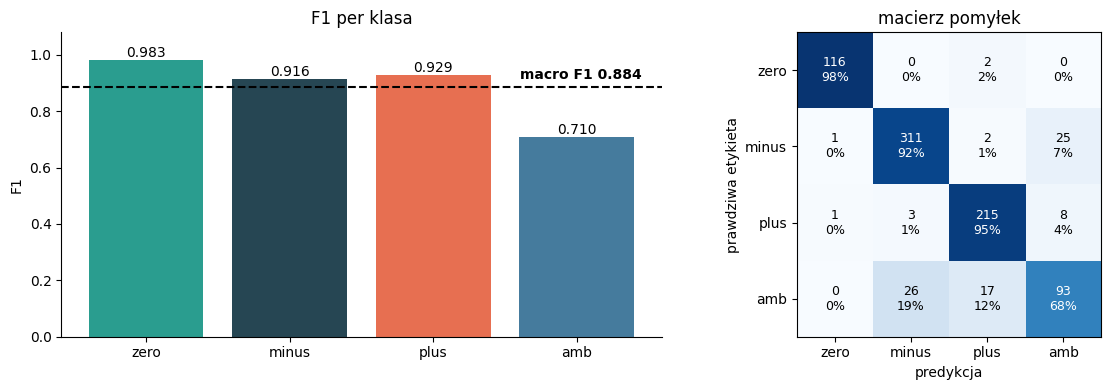

In [8]:
show_run("gpt2-text")

Baseline do porównania: zamrożony GPT-2, trenowana tylko głowica (bez LoRA). Większy learning rate, bo uczy się tylko jedna warstwa.

In [9]:
!python -m src.training.gpt2 --task text --mode head --lr 1e-3 --batch-size 4 --grad-accum 4 --output-dir {OUT}/gpt2-text-head

/content/drive/MyDrive/nlp_lab/outputs/gpt2-text-head ma juz results.json, pomijam (--overwrite trenuje od nowa)


### Wynik na zbiorze testowym: tekst, head

,train,accuracy,macro F1,weighted F1,F1 zero,F1 minus,F1 plus,F1 amb
gpt2-text-head,6573,0.850,0.824,0.844,0.962,0.884,0.892,0.558


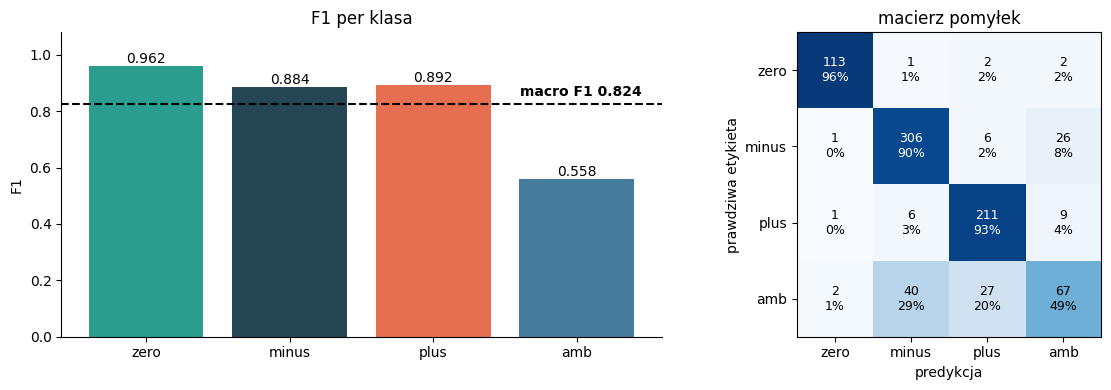

,train,accuracy,macro F1,weighted F1,F1 zero,F1 minus,F1 plus,F1 amb
"tekst, LoRA",6573,0.896,0.884,0.895,0.983,0.916,0.929,0.710
"tekst, head",6573,0.850,0.824,0.844,0.962,0.884,0.892,0.558


**tekst, head**: macro F1 -0.060 względem **tekst, LoRA**

In [10]:
show_run("gpt2-text-head")
show_comparison(["gpt2-text", "gpt2-text-head"])

## Klasyfikacja tokenów

Każde słowo dostaje sentyment swojego zdania. Etykieta tylko na pierwszym subtokenie słowa, `<eos>` i padding mają `-100`.

In [11]:
!python -m src.training.gpt2 --task token --batch-size 4 --grad-accum 4 --output-dir {OUT}/gpt2-token

/content/drive/MyDrive/nlp_lab/outputs/gpt2-token ma juz results.json, pomijam (--overwrite trenuje od nowa)


### Wynik na zbiorze testowym: tokeny, LoRA

,train,accuracy,macro F1,weighted F1,F1 zero,F1 minus,F1 plus,F1 amb
gpt2-token,4451,0.811,0.744,0.806,0.861,0.862,0.785,0.469


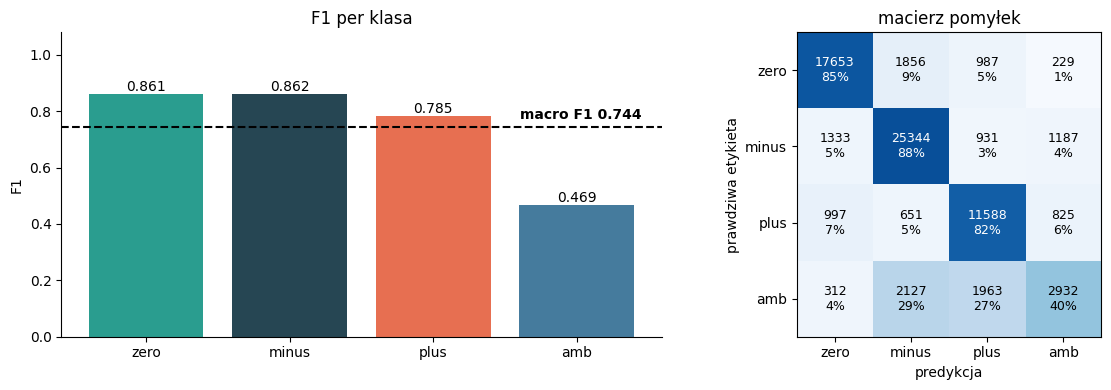

In [12]:
show_run("gpt2-token")

## Embeddingi ostatniego tokenu

Reprezentacja ostatniego prawdziwego tokenu (wejście głowicy klasyfikacyjnej) dla recenzji testowych:
bazowy GPT-2 (LoRA wyłączona) i po strojeniu. Wykresy UMAP i t-SNE, puste znaczniki to błędne predykcje.

In [13]:
if not Path(f"{OUT}/gpt2-text/plots/gpt2_embeddings.npz").exists():
    !python -m src.evaluation.gpt2_embeddings --adapter {OUT}/gpt2-text/adapter

In [23]:
from pathlib import Path
from IPython.display import HTML, display

for name in ["gpt2_base_umap", "gpt2_finetuned_umap"]:
    display(HTML(Path(f"{OUT}/gpt2-text/plots/{name}.html").read_text(encoding="utf-8")))

In [24]:
for name in ["gpt2_base_tsne", "gpt2_finetuned_tsne"]:
    display(HTML(Path(f"{OUT}/gpt2-text/plots/{name}.html").read_text(encoding="utf-8")))

In [15]:
show_embeddings()

### Rozdzielenie klas w przestrzeni embeddingów

,silhouette (cosinus),accuracy
GPT-2 bazowy,0.0489,—
GPT-2 po strojeniu (LoRA),0.3076,0.8963


## Augmentacja generatywna

Początek recenzji treningowej (połowa słów, maks. 40) jest promptem, GPT-2 dopisuje resztę, a nowy tekst
dostaje etykietę recenzji źródłowej. Dwa warianty próbkowania:
`conservative` (temperature 0.7, top-k 50, top-p 0.9) i `diverse` (temperature 1.0, bez top-k, top-p 0.95).

In [16]:
if not Path(f"{AUG}/augmented_gpt2_examples.md").exists():
    !python -m src.data.gpt2_augmentation --max-samples 2000 --output-dir {AUG}

In [17]:
from IPython.display import Markdown

display(Markdown(Path(f"{AUG}/augmented_gpt2_examples.md").read_text(encoding="utf-8")))

| wariant | etykieta | oryginal | po augmentacji (prompt + generacja) |
|---|---|---|---|
| conservative | minus | Chciał em zestaw do podstawowych prac coś przykręcić coś odkręcić - jako , ze nie jestem wielkim majsterkowiczem nie wymagał em wiele jednak sam zestaw jest bardzo mały - wielkości połowy kartki A4 zarówno grzechotka jaki i wkrętak - gubią się w dłoni . Najgorsze jest spasowanie elementów nasadek … | Chciał em zestaw do podstawowych prac coś przykręcić coś odkręcić - jako , ze nie jestem wielkim majsterkowiczem nie wymagał em wiele jednak sam zestaw jest bardzo mały - wielkości połowy kartki A4 zarówno grzechotka jaki i wkrętak - gubią się w nim wszystkie śruby, śrubki itp - nie ma możliwości … |
| conservative | minus | własciwie nic się nie dowidział em , podczas badania usłyszał em , , wszystko mięciutko " i że jest cos zaczerwienione , ale co to jest to niewiadomo , recepta na czopki i jakby się cos działo to , , proszę przyjsć " , akurat za 150 zł na wizytę która razem z badaniem trwała tyle mniej więcej ile … | własciwie nic się nie dowidział em , podczas badania usłyszał em , , wszystko mięciutko " i że jest cos zaczerwienione , ale co to jest to niewiadomo , recepta na czopki i jakby się cos działo to , , że trzeba to zgłosić i jak nie to , że jak nic nie będzie to , albo , że , że to trzeba zrobić. … |
| conservative | zero | Gdy Dominika Nowis zastanawia się , jak zniszczyć raka - zawsze sprawdza , czy jej metody walki nie zniszczą naszych zdrowych organów . To ona jako pierwsza w świecie zbadała , czy inhibitory proteasomu upośledzają funkcję serca . Prace , jakie prowadziła razem z dr . Gaetano Vattemim z … | Gdy Dominika Nowis zastanawia się , jak zniszczyć raka - zawsze sprawdza , czy jej metody walki nie zniszczą naszych zdrowych organów . To ona jako pierwsza w świecie zbadała , czy inhibitory proteasomu upośledzają funkcję serca . Prace , które trwały ponad 100 lat, dowiodły , że inhibitor nie … |
| diverse | minus | Chciał em zestaw do podstawowych prac coś przykręcić coś odkręcić - jako , ze nie jestem wielkim majsterkowiczem nie wymagał em wiele jednak sam zestaw jest bardzo mały - wielkości połowy kartki A4 zarówno grzechotka jaki i wkrętak - gubią się w dłoni . Najgorsze jest spasowanie elementów nasadek … | Chciał em zestaw do podstawowych prac coś przykręcić coś odkręcić - jako , ze nie jestem wielkim majsterkowiczem nie wymagał em wiele jednak sam zestaw jest bardzo mały - wielkości połowy kartki A4 zarówno grzechotka jaki i wkrętak - gubią się młotki (które świetnie się poluzują i dopiero na … |
| diverse | minus | własciwie nic się nie dowidział em , podczas badania usłyszał em , , wszystko mięciutko " i że jest cos zaczerwienione , ale co to jest to niewiadomo , recepta na czopki i jakby się cos działo to , , proszę przyjsć " , akurat za 150 zł na wizytę która razem z badaniem trwała tyle mniej więcej ile … | własciwie nic się nie dowidział em , podczas badania usłyszał em , , wszystko mięciutko " i że jest cos zaczerwienione , ale co to jest to niewiadomo , recepta na czopki i jakby się cos działo to , , że trzeba pisać to : dieta , leki , wizyty . Potem mu udało się dojechać do domu w którym ja … |
| diverse | zero | Gdy Dominika Nowis zastanawia się , jak zniszczyć raka - zawsze sprawdza , czy jej metody walki nie zniszczą naszych zdrowych organów . To ona jako pierwsza w świecie zbadała , czy inhibitory proteasomu upośledzają funkcję serca . Prace , jakie prowadziła razem z dr . Gaetano Vattemim z … | Gdy Dominika Nowis zastanawia się , jak zniszczyć raka - zawsze sprawdza , czy jej metody walki nie zniszczą naszych zdrowych organów . To ona jako pierwsza w świecie zbadała , czy inhibitory proteasomu upośledzają funkcję serca . Prace , na które powołuje się Dominika Nowisa, nie są jedynie … |


In [18]:
show_augmentation()

### Augmentacja: warianty próbkowania

,temperature,top_k,top_p,przykłady,słowa generacji,distinct-1,distinct-2,zero,minus,plus,amb
sampling,,,,,,,,,,,
conservative,0.700000,50,0.900000,1937,44.7,0.169,0.556,287,732,538,380
diverse,1.000000,0,0.950000,1973,46.0,0.288,0.803,295,737,548,393


## Trening na danych augmentowanych

Tak jak w części HerBERTa: train to same wygenerowane przykłady, walidacja i test bez zmian.
Pliki `augmented_mask_*_train.json` z augmentacji HerBERTa obecne w `AUG` trafiają do tego samego treningu
(jeden model na wszystkich augmentacjach).

In [19]:
import glob

files = [f"{AUG}/augmented_gpt2_combined_train.json"] + sorted(glob.glob(f"{AUG}/augmented_mask_*_train.json"))
print(files)
AUG_FILES = " ".join(files)
!python -m src.training.gpt2 --task text --batch-size 4 --grad-accum 4 --augmented {AUG_FILES} --output-dir {OUT}/gpt2-text-augmented

['/content/drive/MyDrive/nlp_lab/augmented/augmented_gpt2_combined_train.json']
/content/drive/MyDrive/nlp_lab/outputs/gpt2-text-augmented ma juz results.json, pomijam (--overwrite trenuje od nowa)


### Wynik na zbiorze testowym: tekst, augmentacja

,train,accuracy,macro F1,weighted F1,F1 zero,F1 minus,F1 plus,F1 amb
gpt2-text-augmented,3910,0.839,0.822,0.837,0.966,0.871,0.876,0.577


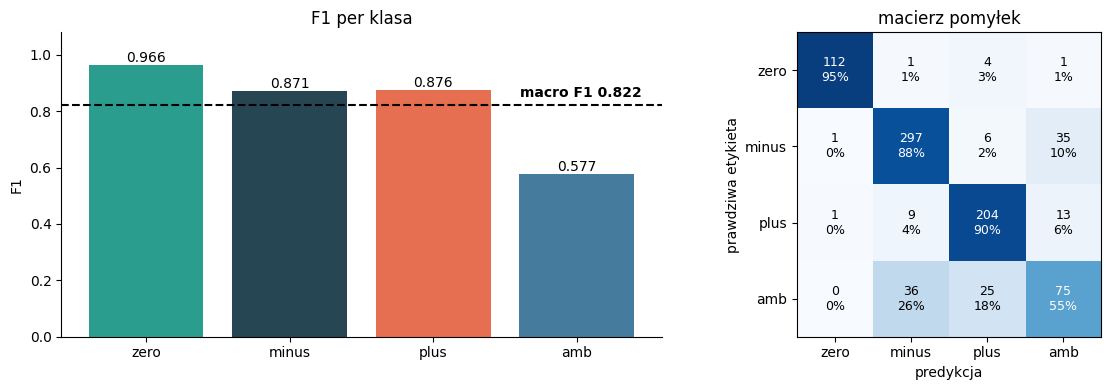

,train,accuracy,macro F1,weighted F1,F1 zero,F1 minus,F1 plus,F1 amb
"tekst, LoRA",6573,0.896,0.884,0.895,0.983,0.916,0.929,0.710
"tekst, augmentacja",3910,0.839,0.822,0.837,0.966,0.871,0.876,0.577


**tekst, augmentacja**: macro F1 -0.062 względem **tekst, LoRA**

In [20]:
show_run("gpt2-text-augmented")
show_comparison(["gpt2-text", "gpt2-text-augmented"])

| przebieg | zadanie | tryb | augmentacja | train | accuracy | macro F1 | Δ macro F1 | F1 zero | F1 minus | F1 plus | F1 amb |
|---|---|---|---|---|---|---|---|---|---|---|---|
| gpt2-text | tekst | lora | nie | 6573 | 0.8963 | 0.8844 | — | 0.9831 | 0.9161 | 0.9287 | 0.7099 |
| gpt2-text-augmented | tekst | lora | tak | 3910 | 0.8390 | 0.8222 | -0.0622 | 0.9655 | 0.8710 | 0.8755 | 0.5769 |
| gpt2-text-head | tekst | head | nie | 6573 | 0.8500 | 0.8242 | — | 0.9617 | 0.8844 | 0.8922 | 0.5583 |
| gpt2-token | tokeny | lora | nie | 4451 | 0.8111 | 0.7442 | — | 0.8607 | 0.8624 | 0.7848 | 0.4689 |



| przebieg | zadanie | tryb | augmentacja | train | accuracy | macro F1 | Δ macro F1 | F1 zero | F1 minus | F1 plus | F1 amb |
|---|---|---|---|---|---|---|---|---|---|---|---|
| gpt2-text | tekst | lora | nie | 6573 | 0.8963 | 0.8844 | — | 0.9831 | 0.9161 | 0.9287 | 0.7099 |
| gpt2-text-augmented | tekst | lora | tak | 3910 | 0.8390 | 0.8222 | -0.0622 | 0.9655 | 0.8710 | 0.8755 | 0.5769 |
| gpt2-text-head | tekst | head | nie | 6573 | 0.8500 | 0.8242 | — | 0.9617 | 0.8844 | 0.8922 | 0.5583 |
| gpt2-token | tokeny | lora | nie | 4451 | 0.8111 | 0.7442 | — | 0.8607 | 0.8624 | 0.7848 | 0.4689 |


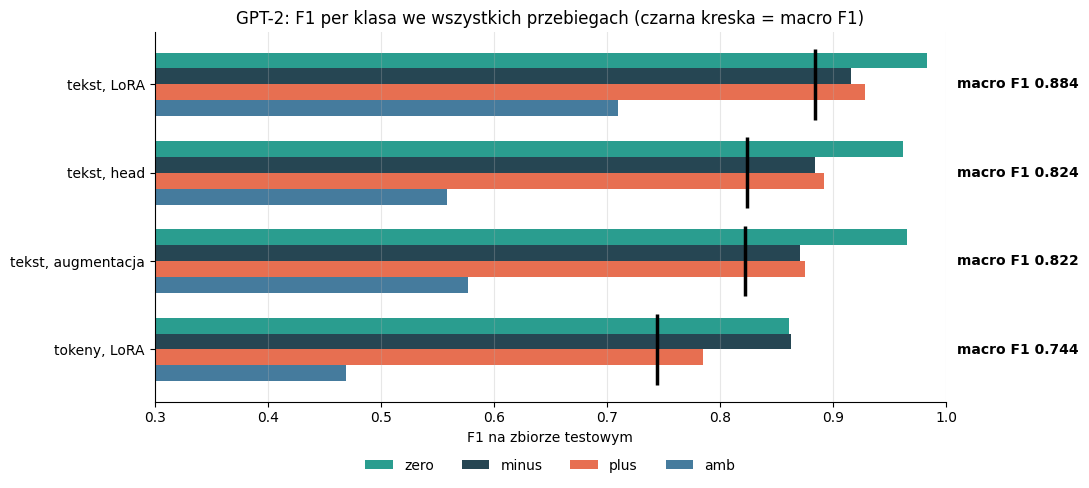

In [21]:
!python -m src.evaluation.gpt2_comparison --root {OUT}
display(Markdown(Path(f"{OUT}/gpt2_comparison.md").read_text(encoding="utf-8")))
show_summary()